# Phase 5: IMA Regulatory Capital, RNIV, IRC (99.9%), Economic Capital, IRRBB & FRTB Transition
**Internal Models Approach (IMA) Quantitative Market Risk & Capital Analytics Suite ($10,000,000 Multi-Asset Desk)**

### Executive Objective
This notebook implements the complete institutional Market Risk Capital & Balance Sheet Analytics suite required by global investment banks operating under the **Internal Models Approach (IMA)**:
1. **Five-Pillar Multi-Asset VaR & ES Attribution:** Explicit coverage and Euler Component VaR decomposition across all five regulatory risk classes: **Rates (`TLT`), FX (`FXE`), Credit (`LQD`), Inflation (`TIP`, `GLD`), and Equity (`SPY`, `AAPL`)**.
2. **RNIV (Risks Not In VaR) Capital Add-On Engine:** Quantifying missing-basis and unmodeled-surface risks omitted by standard VaR engines—specifically **Volatility Smile/Skew Surface Basis (`SPY` Options)**, **Yield-Curve Tenor & Convexity Basis (5Y IRS vs. 20Y Proxy)**, and **Credit Index-to-Single-Name Dispersion Basis**—across both Current and Stressed windows.
3. **IRC (Incremental Risk Charge — 1-Year 99.9%) & Economic Capital Engine:** A **Merton (1974) Single-Factor Gaussian Copula Monte Carlo engine ($M = 50,000$)** modeling 1-year credit default losses ($\text{PD} \times \text{LGD}$) and credit rating migration mark-to-market spread losses across a $\$3,000,000$ corporate bond book, integrated with 1-year market risk tail losses to compute **1-Year 99.9% Enterprise Economic Capital**.
4. **IRRBB (Interest Rate Risk in the Banking Book — BCBS d368):** Evaluating **$\Delta\text{EVE}$ (Economic Value of Equity)** and **1-Year $\Delta\text{NII}$ (Net Interest Income)** across all **6 Basel Standard Supervisory Interest-Rate Shock Scenarios** ($\pm 200\text{ bps}$ Parallel, Steepener, Flattener, Short Rate Up/Down) and verifying how an ALCO 5Y Pay-Fixed Swap hedge brings the balance sheet inside the **Basel 15% Tier-1 Capital Outlier limit**.
5. **Transition to FRTB (BCBS d457):** Computing **Liquidity-Horizon-Adjusted $97.5\%$ Expected Shortfall** across statutory Basel liquidity horizons ($LH \in \{10, 20, 40\}\text{ days}$), running the **Acerbi & Székely (2014) $Z_2$ ES Backtest**, and building the **Basel 2.5 vs. FRTB IMA Total Capital Bridge**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data
from src.regulatory_capital_frtb import (
    compute_five_pillar_var_attribution,
    compute_rniv_capital_addons,
    simulate_irc_and_economic_capital,
    evaluate_irrbb_supervisory_shocks,
    compute_frtb_liquidity_adjusted_es,
    acerbi_szekely_es_backtest,
    build_ima_regulatory_capital_bridge,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (14, 5.2)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
bundle = prepare_and_save_processed_data(cfg)
arith_returns = bundle["arith_returns"]
vix_df = bundle["vix"]
notional_usd = float(cfg["portfolio"]["notional_usd"])

## 1. Five-Pillar Multi-Asset VaR & Expected Shortfall Attribution (`Rates, FX, Credit, Inflation, Equity`)
Below we decompose the $\$10,000,000$ multi-asset book across all five regulatory risk classes using Euler Component VaR and quantify the cross-asset diversification benefit contributed by each pillar.

In [2]:
inst_df, pillar_df = compute_five_pillar_var_attribution(arith_returns, notional_usd=notional_usd, alpha=0.99)
print(f"Total Diversified 5-Pillar 1-Day 99% VaR : ${pillar_df['Component_VaR_99_USD'].sum():,.2f}")
print(f"Sum of Standalone 5-Pillar 1-Day 99% VaRs: ${pillar_df['Standalone_VaR_99_USD'].sum():,.2f}")
print(f"Cross-Pillar Diversification Benefit     : ${pillar_df['Diversification_Benefit_USD'].sum():,.2f}")
pillar_df.round(2)

Total Diversified 5-Pillar 1-Day 99% VaR : $119,246.39
Sum of Standalone 5-Pillar 1-Day 99% VaRs: $192,532.33
Cross-Pillar Diversification Benefit     : $73,285.94


,Risk_Class_Pillar,Weight_pct,Notional_USD,Standalone_VaR_99_USD,Component_VaR_99_USD,Component_ES_99_USD,Share_of_Total_VaR_pct,Diversification_Benefit_USD
0,Equity,35.0,3500000.0,101947.65,82223.53,94297.91,68.95,19724.11
1,Credit,15.0,1500000.0,17159.58,12089.15,13888.04,10.14,5070.43
2,Rates,20.0,2000000.0,36639.82,10814.36,12227.88,9.07,25825.46
3,FX,15.0,1500000.0,17423.77,7817.46,8909.27,6.56,9606.31
4,Inflation,15.0,1500000.0,19361.51,6301.88,7201.75,5.28,13059.63


In [3]:
inst_df.round(2)

,Ticker,Risk_Class_Pillar,Risk_Factor_Description,Weight_pct,Notional_USD,Ann_Vol_pct,Standalone_VaR_99_USD,Component_VaR_99_USD,Component_ES_99_USD,Share_of_Total_VaR_pct
0,SPY,Equity,US Large-Cap Equity Beta (SPY),22.0,2200000.0,16.70,53820.47,43843.55,50230.85,36.77
1,AAPL,Equity,US Single-Stock Tech Equity (AAPL),13.0,1300000.0,25.61,48127.18,38379.99,44067.06,32.19
2,TLT,Rates,US 20+ Yr Sovereign Treasury Duration (TLT),20.0,2000000.0,12.12,36639.82,10814.36,12227.88,9.07
3,FXE,FX,G10 Foreign Exchange Spot EUR/USD (FXE),15.0,1500000.0,7.78,17423.77,7817.46,8909.27,6.56
4,LQD,Credit,US Investment-Grade Corporate Credit Spread (LQD),15.0,1500000.0,7.92,17159.58,12089.15,13888.04,10.14
5,TIP,Inflation,US TIPS Inflation Breakeven & Real Yield (TIP),10.0,1000000.0,6.87,10044.59,3100.40,3555.42,2.60
6,GLD,Inflation,Precious Metals / Inflation Tail Hedge (GLD),5.0,500000.0,12.51,9316.93,3201.49,3646.33,2.68


## 2. RNIV (Risks Not In VaR) Capital Add-On Framework
Standard VaR engines rely on reduced-form risk factors (e.g., flat ATM VIX shocks for equity options, parallel 20Y duration proxies for swaps, and index-level credit spreads). The **RNIV framework** captures the 99% tail loss of the unmodeled basis across three channels in both Current and Stressed (2020 COVID) windows:
1. **Volatility Smile / Skew Surface Basis (`SPY` Options)**
2. **Yield-Curve Tenor & Convexity Basis (5Y IRS vs. 20Y Proxy)**
3. **Credit Spread Index-to-Issuer Dispersion Basis (`LQD` vs. Single-Name Issuers)**

In [4]:
rniv_df, rniv_sum = compute_rniv_capital_addons(arith_returns, vix_df, alpha=0.99)
for k, v in rniv_sum.items():
    print(f"  {k:36s}: ${v:,.2f}")
rniv_df.round(2)

  total_rniv_1d_99_var_usd            : $24,351.89
  total_stressed_rniv_1d_99_var_usd   : $74,698.88
  total_rniv_capital_charge_usd       : $297,152.32


,RNIV_1d_99_VaR_USD,RNIV_1d_99_ES_USD,Stressed_RNIV_1d_99_VaR_USD,Stressed_RNIV_1d_99_ES_USD,Regulatory_RNIV_Capital_Charge_USD
RNIV_Risk_Factor_Channel,,,,,
Volatility Smile / Skew Surface Basis (SPY Options),4000.99,4291.63,12147.68,12850.49,48446.04
Yield-Curve Tenor & Convexity Basis (5Y IRS vs 20Y Proxy),13081.28,15174.61,41710.50,53913.00,164375.35
Credit Spread Index-to-Issuer Basis ($1.5M Credit Sleeve),7269.61,8659.88,20840.70,27274.31,84330.93


## 3. IRC (Incremental Risk Charge — 1-Year 99.9%) & Enterprise Economic Capital
Using a **Merton (1974) Single-Factor Gaussian Copula ($M = 50,000$ simulations)**:
$$Z_i = \sqrt{\rho_i} \, M_{\text{sys}} + \sqrt{1 - \rho_i} \, \varepsilon_i$$
we simulate 1-year credit default losses ($\text{PD}_i \times \text{LGD}_i \times \text{EAD}_i$) and credit rating migration mark-to-market spread losses ($\text{Duration}_i \times \Delta \text{Spread}_i \times \text{EAD}_i$) at the **99.9% confidence level** across a $\$3,000,000$ 6-obligor credit book, and combine it with 1-year 99.9% market risk losses ($\rho_{\text{Mkt,Cred}} = 0.35$) to compute **Enterprise Economic Capital**.

In [5]:
irc_df, irc_sum = simulate_irc_and_economic_capital(num_simulations=50_000, seed=42)
for k, v in irc_sum.items():
    unit = "%" if "pct" in k else "$"
    print(f"  {k:44s}: {unit}{v:,.2f}")
irc_df.round(2)

  credit_book_notional_usd                    : $3,000,000.00
  expected_credit_loss_1y_usd                 : $26,768.82
  drc_default_only_999_usd                    : $460,000.00
  irc_default_plus_migration_999_usd          : $503,000.00
  migration_share_of_irc_pct                  : %8.55
  irc_es_999_usd                              : $577,305.69
  standalone_market_ec_999_usd                : $1,738,781.89
  standalone_credit_ec_999_usd                : $476,231.18
  diversified_total_economic_capital_999_usd  : $1,814,058.64
  ec_diversification_benefit_usd              : $400,954.44
  total_ec_es_999_usd                         : $2,217,062.45


,Obligor,Rating,Notional_EAD_USD,Annual_PD_pct,LGD_pct,Asset_Correlation_rho,Modified_Duration_Yrs,Expected_Default_Loss_USD,Expected_Migration_Loss_USD,Simulated_999_Loss_Contribution_USD
0,Obligor 1 (Tech IG - AA),AA,600000.0,0.04,40.0,0.18,4.5,96.0,627.75,14326.91
1,Obligor 2 (Financials IG - A),A,600000.0,0.12,45.0,0.20,4.2,324.0,1197.00,48865.07
2,Obligor 3 (Industrial IG - BBB+),BBB+,500000.0,0.28,45.0,0.22,4.8,630.0,2544.00,70869.03
3,Obligor 4 (Energy IG - BBB),BBB,500000.0,0.45,50.0,0.24,4.0,1125.0,3340.00,159425.74
4,Obligor 5 (Consumer Crossover - BB+),BB+,400000.0,1.25,55.0,0.22,3.6,2750.0,4032.00,112156.80
5,Obligor 6 (High-Yield Telecom - BB),BB,400000.0,2.10,60.0,0.20,3.2,5040.0,5241.60,165312.00


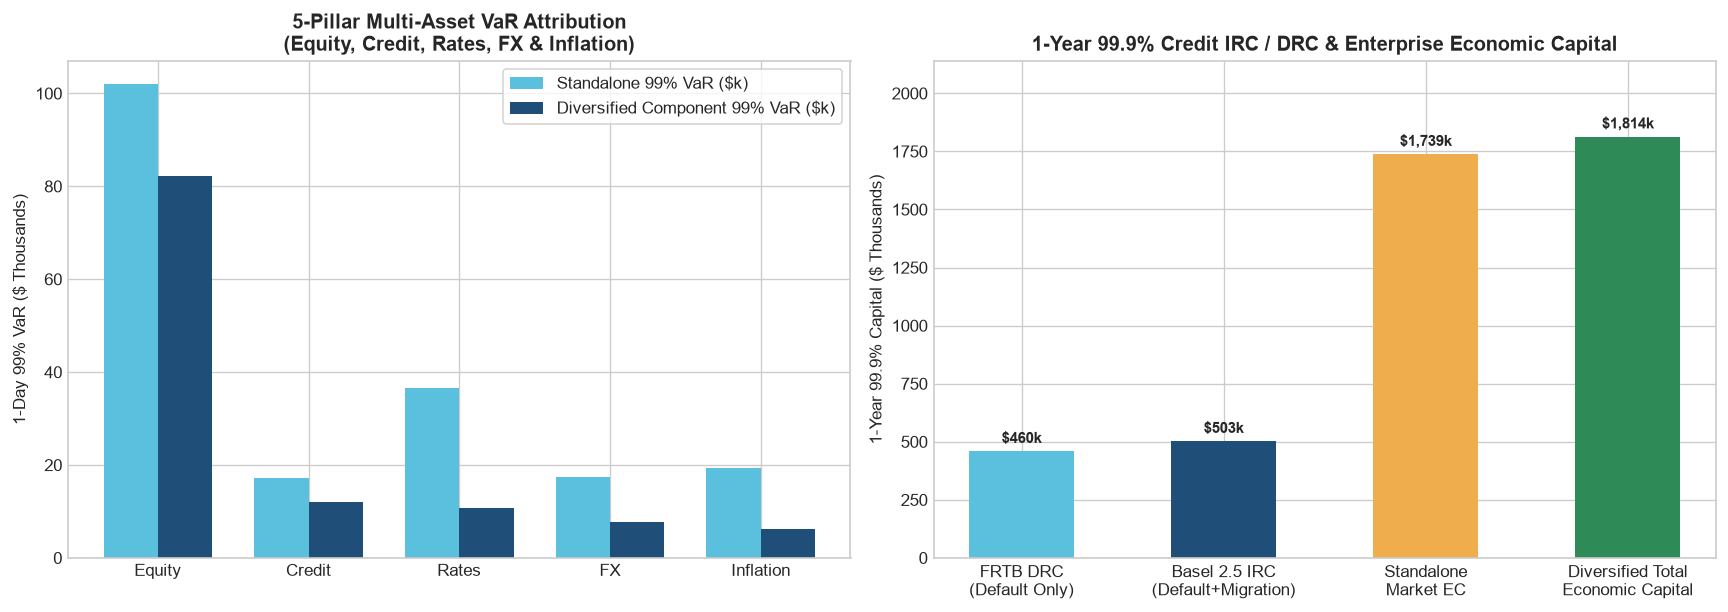

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

# Left Panel: 5-Pillar Standalone vs Diversified Component VaR
x_p = np.arange(len(pillar_df))
w_b = 0.36
axes[0].bar(x_p - w_b/2, pillar_df["Standalone_VaR_99_USD"] / 1e3, width=w_b, color="#5bc0de", label="Standalone 99% VaR ($k)")
axes[0].bar(x_p + w_b/2, pillar_df["Component_VaR_99_USD"] / 1e3, width=w_b, color="#1f4e78", label="Diversified Component 99% VaR ($k)")
axes[0].set_xticks(x_p)
axes[0].set_xticklabels(pillar_df["Risk_Class_Pillar"])
axes[0].set_title("5-Pillar Multi-Asset VaR Attribution\n(Equity, Credit, Rates, FX & Inflation)", fontweight="bold")
axes[0].set_ylabel("1-Day 99% VaR ($ Thousands)")
axes[0].legend(frameon=True)

# Right Panel: IRC (Default vs Migration) & Enterprise Economic Capital (1Y 99.9%)
ec_labels = ["FRTB DRC\n(Default Only)", "Basel 2.5 IRC\n(Default+Migration)", "Standalone\nMarket EC", "Diversified Total\nEconomic Capital"]
ec_vals = [
    irc_sum["drc_default_only_999_usd"] / 1e3,
    irc_sum["irc_default_plus_migration_999_usd"] / 1e3,
    irc_sum["standalone_market_ec_999_usd"] / 1e3,
    irc_sum["diversified_total_economic_capital_999_usd"] / 1e3,
]
colors_ec = ["#5bc0de", "#1f4e78", "#f0ad4e", "#2e8b57"]
axes[1].bar(ec_labels, ec_vals, color=colors_ec, width=0.52)
for idx, val in enumerate(ec_vals):
    axes[1].text(idx, val + 35, f"${val:,.0f}k", ha="center", fontweight="bold", fontsize=9)
axes[1].set_ylim(0, max(ec_vals) * 1.18)
axes[1].set_title("1-Year 99.9% Credit IRC / DRC & Enterprise Economic Capital", fontweight="bold")
axes[1].set_ylabel("1-Year 99.9% Capital ($ Thousands)")

plt.tight_layout()
plt.show()

## 4. IRRBB (Interest Rate Risk in the Banking Book — BCBS d368)
We evaluate a representative $\$100,000,000$ Banking Book across 8 repricing tenor buckets (`1M` to `20Y`) under all **6 Basel Standard Supervisory Interest-Rate Shock Scenarios**. Notice how the unhedged balance sheet breaches the **Basel 15% Tier-1 Capital Outlier threshold** under the $+200\text{ bps}$ Parallel Up shock ($-\$3.09\text{M}$, or $-20.6\%$ of $\$15\text{M}$ Tier-1 capital), whereas adding the **$\$10\text{M}$ 5-Year Pay-Fixed ALCO Swap Hedge** generates $+\$848.7\text{k}$ in hedge gains, bringing Hedged $\Delta\text{EVE}$ to $-\$2.24\text{M}$ ($-14.93\%$ of Tier-1 capital, passing the 15% outlier test across all 6 scenarios).

In [7]:
gap_table, irrbb_table = evaluate_irrbb_supervisory_shocks(tier1_capital_usd=15_000_000.0)
irrbb_table.round(2)

,Short_End_1M_Shock_bps,Long_End_10Y_Shock_bps,Unhedged_Delta_EVE_USD,ALCO_5Y_Swap_Hedge_PnL_USD,Hedged_Delta_EVE_USD,Delta_EVE_pct_Tier1_Capital,Delta_NII_1Y_USD,Basel_15pct_Outlier_Pass
Supervisory_Shock_Scenario,,,,,,,,
1. Parallel Up (+200 bps),200.00,200.00,-3088345.64,848683.46,-2239662.19,-14.93,111335.80,True
2. Parallel Down (-200 bps),-200.00,-200.00,3927284.75,-942069.69,2985215.07,19.90,-111335.80,False
3. Steepener (Short -160 / Long +90 bps),-157.30,69.27,-1136118.06,78529.55,-1057588.50,-7.05,-84721.20,True
4. Flattener (Short +200 / Long -60 bps),194.64,-38.66,686990.10,64501.06,751491.16,5.01,105426.20,True
5. Short Rate Up (+250 bps),244.85,20.52,-356766.21,314117.75,-42648.46,-0.28,133487.44,True
6. Short Rate Down (-250 bps),-244.85,-20.52,369597.77,-326082.58,43515.20,0.29,-133487.44,True


## 5. FRTB Liquidity-Horizon-Adjusted ES ($97.5\%$) & Basel 2.5 vs. FRTB Capital Bridge
Under the **Fundamental Review of the Trading Book (FRTB, BCBS d457)**, 10-day $99\%$ VaR is replaced by **Liquidity-Horizon-Adjusted $97.5\%$ Expected Shortfall** across statutory liquidity horizons $LH_j \in \{10, 20, 40, 60, 120\}$ days:
$$\text{ES}_{\text{FRTB}} = \sqrt{ \left(\text{ES}_{10\text{d}}(P)\right)^2 + \sum_{j \ge 2} \left( \text{ES}_{10\text{d}}(P, j) \sqrt{\frac{LH_j - LH_{j-1}}{10}} \right)^2 }$$

In [8]:
frtb_buckets_df, frtb_sum = compute_frtb_liquidity_adjusted_es(arith_returns, vix_df, notional_usd=notional_usd, alpha_frtb=0.975)
for k, v in frtb_sum.items():
    unit = "%" if "pct" in k else "$"
    print(f"  {k:44s}: {unit}{v:,.2f}")
frtb_buckets_df.round(2)

  es_975_1d_current_usd                       : $122,289.90
  es_975_10d_unadjusted_current_usd           : $386,714.63
  frtb_liquidity_adjusted_es_current_usd      : $427,390.53
  frtb_liquidity_adjusted_es_stressed_usd     : $962,410.19
  liquidity_horizon_addon_pct                 : %10.52
  frtb_imak_multiplier_1_5_charge_usd         : $1,443,615.28


,Cascade_Bucket,Liquidity_Horizon_Days,Incremental_Scale_Factor,Base_10d_ES_975_Current_USD,Scaled_Cascade_Term_Current_USD,Base_10d_ES_975_Stressed_USD,Scaled_Cascade_Term_Stressed_USD
0,"Bucket 1 (LH >= 10d: Equity, Sovereign Rates, ...",10,1.00,386714.63,386714.63,841920.37,841920.37
1,"Bucket 2 (LH >= 20d: FX, IG Credit, Inflation)",20,1.00,122332.33,122332.33,277947.22,277947.22
2,Bucket 3 (LH >= 40d: IG Credit Spreads & Infla...,40,1.41,95260.86,134719.20,264715.71,374364.54


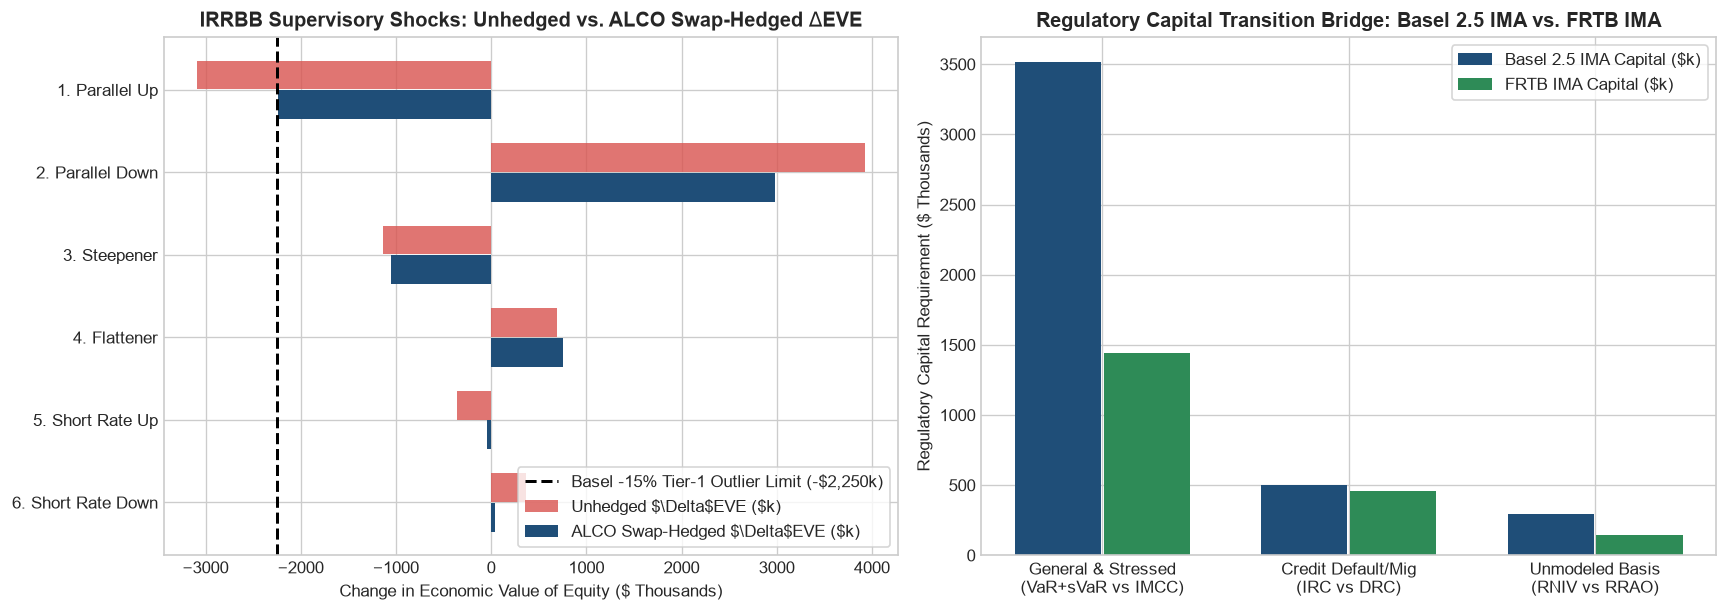

,Basel_2_5_IMA_Capital_USD,FRTB_IMA_Capital_USD,Methodology_Transition_Note
Capital_Component,,,
1. General & Stressed Market Risk (VaR+sVaR vs. FRTB IMCC ES_LH),3518591.29,1443615.28,"Replaces 3x(VaR_99,10d + sVaR_99,10d) with 1.5..."
2. Credit Default & Migration Risk (IRC vs. FRTB DRC),503000.00,460000.00,1Y 99.9% Copula; FRTB moves migration spread r...
3. Unmodeled Basis & Exotic Risks (RNIV vs. FRTB RRAO/SES),297152.32,148576.16,"Captures Vol Skew Basis, Yield-Curve Convexity..."
TOTAL REGULATORY IMA MARKET RISK CAPITAL,4318743.60,2052191.44,1-Year 99.9% Internal Economic Capital Benchma...


In [9]:
capital_bridge_df = build_ima_regulatory_capital_bridge(arith_returns, vix_df, notional_usd=notional_usd)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

# Left Panel: IRRBB Unhedged vs Hedged Delta EVE across the 6 Basel Supervisory Shocks
y_pos = np.arange(len(irrbb_table))
axes[0].barh(y_pos - 0.18, irrbb_table["Unhedged_Delta_EVE_USD"] / 1e3, height=0.35, color="#d9534f", alpha=0.8, label="Unhedged $\\Delta$EVE ($k)")
axes[0].barh(y_pos + 0.18, irrbb_table["Hedged_Delta_EVE_USD"] / 1e3, height=0.35, color="#1f4e78", label="ALCO Swap-Hedged $\\Delta$EVE ($k)")
axes[0].axvline(-0.15 * 15000, color="black", ls="--", lw=1.8, label="Basel -15% Tier-1 Outlier Limit (-$2,250k)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([s.split("(")[0].strip() for s in irrbb_table.index])
axes[0].invert_yaxis()
axes[0].set_title("IRRBB Supervisory Shocks: Unhedged vs. ALCO Swap-Hedged $\\Delta$EVE", fontweight="bold")
axes[0].set_xlabel("Change in Economic Value of Equity ($ Thousands)")
axes[0].legend(loc="lower right", frameon=True)

# Right Panel: Basel 2.5 vs FRTB IMA Regulatory Capital Bridge
comp_rows = capital_bridge_df.iloc[:-1]
x_c = np.arange(len(comp_rows))
axes[1].bar(x_c - 0.18, comp_rows["Basel_2_5_IMA_Capital_USD"] / 1e3, width=0.35, color="#1f4e78", label="Basel 2.5 IMA Capital ($k)")
axes[1].bar(x_c + 0.18, comp_rows["FRTB_IMA_Capital_USD"] / 1e3, width=0.35, color="#2e8b57", label="FRTB IMA Capital ($k)")
axes[1].set_xticks(x_c)
axes[1].set_xticklabels(["General & Stressed\n(VaR+sVaR vs IMCC)", "Credit Default/Mig\n(IRC vs DRC)", "Unmodeled Basis\n(RNIV vs RRAO)"])
axes[1].set_title("Regulatory Capital Transition Bridge: Basel 2.5 IMA vs. FRTB IMA", fontweight="bold")
axes[1].set_ylabel("Regulatory Capital Requirement ($ Thousands)")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

capital_bridge_df.round(2)